In [59]:
import pandas as pd
import numpy as np


In [60]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from sklearn.preprocessing import KBinsDiscretizer

from sklearn.compose import ColumnTransformer

In [61]:
df = pd.read_csv(r"C:\Users\Mozassam Imam\Desktop\AI\CampusX\ML\19_Understanding_data\train_titanic.csv",usecols = ['Age', 'Fare', 'Survived'])

In [62]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [63]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [64]:
df.dropna(inplace=True)

In [65]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [66]:
df.shape

(714, 3)

In [67]:
X=df.iloc[:,1:]
y=df.iloc[:,:1]

In [68]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [69]:
X_train.head()

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542
253,30.0,16.1000
719,33.0,7.7750
666,25.0,13.0000


In [70]:
y_train.head()

,Survived
328,1
73,0
253,0
719,0
666,0


In [71]:
clf=DecisionTreeClassifier()

In [72]:
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

In [73]:
accuracy_score(y_test,y_pred)

0.6223776223776224

In [74]:
np.mean(cross_val_score(clf,X,y,scoring='accuracy'))

0.6218556091795528

Descritizer

In [75]:
KBin_age=KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')
KBin_fare=KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')

In [76]:
trf=ColumnTransformer([
    ('first',KBin_age,[0]),
    ('second',KBin_fare,[1])
])

In [77]:
X_train_trf=trf.fit_transform(X_train)
X_test_trf=trf.transform(X_test)

In [78]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [79]:
trf.named_transformers_['first'].n_bins_

array([15])

In [80]:
output=pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})

In [81]:
output.head()

,age,age_trf,fare,fare_trf
328,31.0,8.0,20.5250,8.0
73,26.0,6.0,14.4542,7.0
253,30.0,8.0,16.1000,7.0
719,33.0,9.0,7.7750,2.0
666,25.0,6.0,13.0000,6.0


In [82]:
output['age_labels'] = pd.cut(x=X_train['Age'],
                                    bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
                                    bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [83]:
output.head()

,age,age_trf,fare,fare_trf,age_labels,fare_labels
328,31.0,8.0,20.5250,8.0,"(30.0, 32.0]","(18.75, 26.0]"
73,26.0,6.0,14.4542,7.0,"(25.0, 28.0]","(13.0, 14.454]"
253,30.0,8.0,16.1000,7.0,"(28.0, 30.0]","(14.454, 18.75]"
719,33.0,9.0,7.7750,2.0,"(32.0, 35.0]","(7.25, 7.775]"
666,25.0,6.0,13.0000,6.0,"(23.0, 25.0]","(10.5, 13.0]"


In [84]:
clf = DecisionTreeClassifier()

In [85]:
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

In [86]:
accuracy_score(y_test,y_pred2)

0.6363636363636364

In [87]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(clf,X_trf,y,scoring='accuracy'))

0.6387471683246331

In [88]:
import matplotlib.pyplot as plt

In [89]:
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    
    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second',kbin_fare,[1])
    ])
    
    X_trf = trf.fit_transform(X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy')))
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Fare'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,1],color='red')
    plt.title("Fare")

    plt.show()

0.6275039123630674


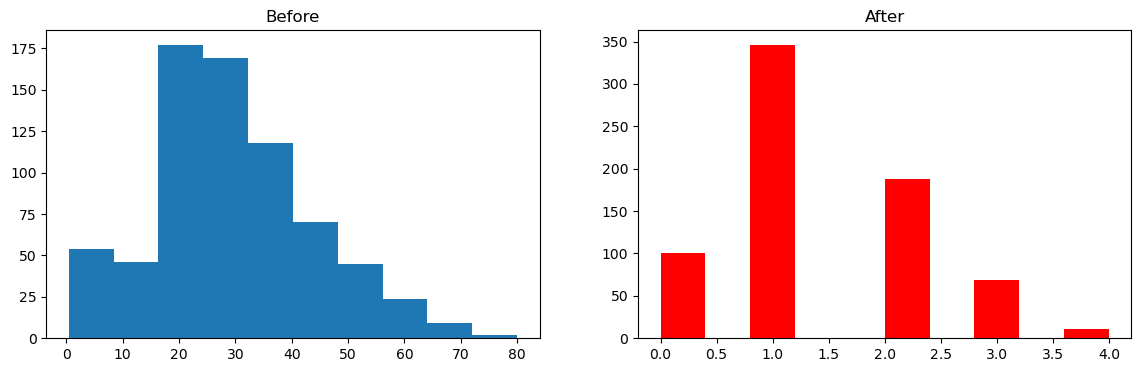

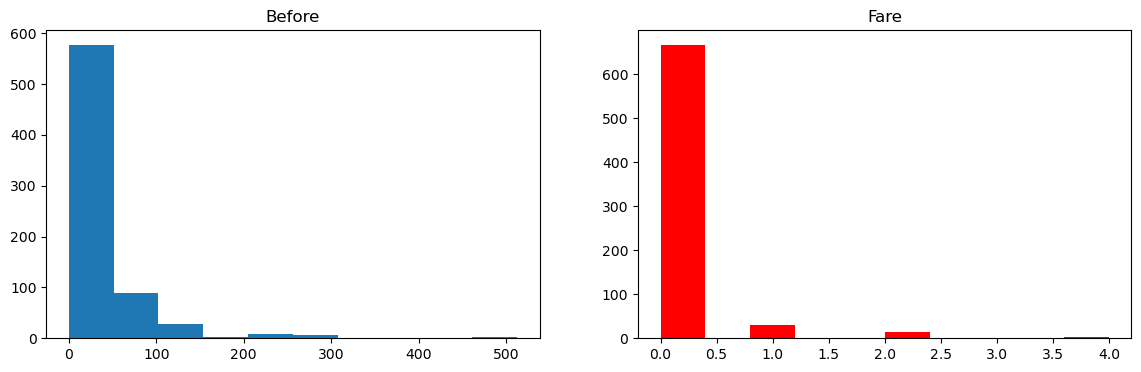

In [91]:
discretize(5,'uniform')